## Preliminaries

Freeze backbone from ResNet trained in `ResNet_Train.ipynb` and fit a simple classifier on top to recognize the three discriminant concepts: *fluffy yellow black stripes*, *fluffy dark orange*, *smooth black thin brown stripes*.

The concepts database was created with Stable Diffusion 1.5: https://beta.dreamstudio.ai/dream

Note: start the Jupyter server from the console within the folder `/mnt/KInsektDaten/teo`.

In [1]:
#import os
#os.chdir('C:\\Users\\Teo\\Documents\\Projects') # equivalent to /teo on server
#os.chdir('../..') # when running code in the server folder from your laptop, you start in the /notebooks folder
#print(os.getcwd())

!pwd
import sys, os
sys.path.append('./wingbeats/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
import datetime
import glob
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, TensorBoard
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from beexplainable.beexplainable.preprocessing import dataset_transformers as dt
from wingbeats import modelling as wm # for building simple classifiers

No module named 'nltk'


In [3]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2023-02-06 13:40:37.527705: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-02-06 13:40:38.080415: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 47187 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [4]:
spec_subfolder = '6_species/'
CONCEPTS_PATH = '../data/Wildbienen/Concepts_Bombus_vs_Andrena_masks/'

MODELS_PATH  = './beexplainable/models/'
FIGURES_PATH = './beexplainable/figures/training_curves/'

In [5]:
# Store concepts, image paths and create label vector from subfolder names
concepts, concept_files, y_true = [], [], []
concept_subfolders = sorted( glob.glob(CONCEPTS_PATH + '*') )
for i in range(len(concept_subfolders)):
    # Add concept from subfolder base name
    concept = os.path.basename(concept_subfolders[i])
    concepts.append( concept )

    # Get image paths in current concept subfolder (there are .jpg and .png files)
    c_files = glob.glob(CONCEPTS_PATH + concept + '/*.jpg') + glob.glob(CONCEPTS_PATH + concept + '/*.png')
    concept_files += [c[len(CONCEPTS_PATH):] for c in c_files] # remove the constant path to the common dir.
    y_true += [i] * len(c_files)

In [6]:
concepts

['fluffy_dark_orange',
 'fluffy_yellow_black_stripes',
 'smooth_black_thin_brown_stripes']

## Load images

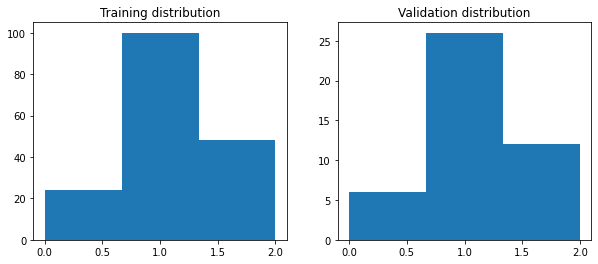

In [7]:
batch_size = 64
img_height = img_width = 224

# Define file ids (for consistency with the parsers in the pipeline)
# Note: the metafile readers return a Dict[str, str]
file_ids = [str(i) for i in range(1, len(y_true)+1)]

# Split into training and validation
train_files, val_files, y_train, y_val = train_test_split(file_ids, y_true, test_size = 0.2, random_state = 2022,
                                                          shuffle = True, stratify = y_true)

plt.figure(figsize = (10, 4))
plt.subplot(121)
plt.hist(y_train, bins = len(np.unique(y_train)))
plt.title('Training distribution')

plt.subplot(122)
plt.hist(y_val, bins = len(np.unique(y_val)))
plt.title('Validation distribution')
plt.show()

In [8]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids, concept_files),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, CONCEPTS_PATH),
                                          label)

2023-02-06 13:40:38.279832: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 47187 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [9]:
# Conversion to tf.Dataset
train_set = ps.parse_to_dataset(train_files, y_train, parse_image_lab)
augment = True
if augment:
    train_set = dt.augment_dataset(train_set)
train_set = train_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

val_set = ps.parse_to_dataset(val_files, y_val, parse_image_lab)
val_set = val_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
train_set = train_set.map(lambda x, y: (normalization_layer(x), y))
val_set   = val_set.map(lambda x, y: (normalization_layer(x), y))

2023-02-06 13:40:39.338941: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


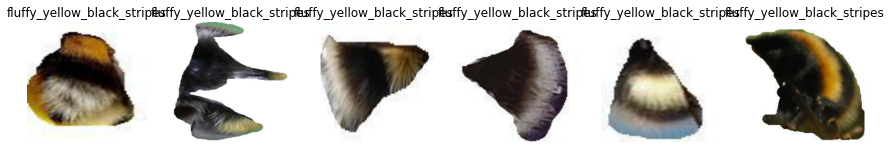

In [10]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = min(6, batch_size)
with tf.device('/CPU:0'):
    for images, labels in train_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(concepts[labels[i].numpy()])
            plt.axis("off")
plt.show()

In [11]:
for image_batch, labels_batch in train_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(64, 224, 224, 3)
tf.Tensor(1, shape=(), dtype=int32)


2023-02-06 13:40:39.730686: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


## Training

In [12]:
# Define initial training and other model parameters
epochs, drop_rate = 10, 0.5
lr, reg = 1e-3, 1e-3 # parameters optimized in HPO notebook
in_shape = (img_width, img_height, 3)

constructor, out_shape =  wm.build_simple_classifier, len(concepts)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy']

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
input_form = 'masked_bbox' # raw, masked, bbox, masked_bbox
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_' + input_form + '_3concepts_masks'
save_weights_file = MODELS_PATH + 'all/' + spec_subfolder + model_name + '/' + model_name + '.h5' # where to save new weights

# Logs directory for TensorBoard
logs_dir = MODELS_PATH + 'all/' + spec_subfolder + model_name + '/logs/'

# History folder
history_dir = MODELS_PATH + 'all/' + spec_subfolder + model_name + '/histories/'

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = False

In [13]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = False,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(MODELS_PATH + 'all/' + spec_subfolder + \
                   'ResNet50_iNat_masked_bbox_6spec_2/ResNet50_iNat_masked_bbox_6spec_2.h5',
                   by_name = True, skip_mismatch = True)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

# Callbacks
checkPoint = ModelCheckpoint(filepath = save_weights_file, save_best_only = True,  monitor = 'val_accuracy', verbose = 1)
earlyStopper = EarlyStopping(monitor = 'val_accuracy', min_delta = 1e-2, patience = 5, verbose = 1)
lr_sched = ReduceLROnPlateau(monitor = 'val_accuracy', factor = 0.1, min_delta = 1e-1, min_lr = lr * 0.01,
                             patience = 3, verbose = 1)
tensorBoard = TensorBoard(log_dir = logs_dir + datetime.datetime.now().strftime("%Y%m%d-%H%M%S"),
                          histogram_freq = 1, write_graph = True, write_images = True)
model_callbacks = [checkPoint, earlyStopper, lr_sched, tensorBoard]

### Masks as concepts

In [14]:
# Train on the 3 concepts (masked_bbox_2), lr=reg=1e-3
history = model.fit(train_set, epochs = epochs,
                    validation_data = val_set, callbacks = model_callbacks)

Epoch 1/10


2023-02-06 13:42:16.188923: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2023-02-06 13:42:16.728734: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-02-06 13:42:16.729649: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-02-06 13:42:16.729702: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2023-02-06 13:42:16.730925: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-02-06 13:42:16.731068: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


17/17 [==============================] - ETA: 0s - loss: 79.8788 - accuracy: 0.5048
Epoch 1: val_accuracy improved from -inf to 0.65909, saving model to ./beexplainable/models/all/6_species/ResNet50_iNat_masked_bbox_3concepts_masks/ResNet50_iNat_masked_bbox_3concepts_masks.h5
17/17 [==============================] - 14s 544ms/step - loss: 79.8788 - accuracy: 0.5048 - val_loss: 79.6280 - val_accuracy: 0.6591 - lr: 0.0010
Epoch 2/10
16/17 [===========================>..] - ETA: 0s - loss: 79.6194 - accuracy: 0.6318
Epoch 2: val_accuracy improved from 0.65909 to 0.68182, saving model to ./beexplainable/models/all/6_species/ResNet50_iNat_masked_bbox_3concepts_masks/ResNet50_iNat_masked_bbox_3concepts_masks.h5
17/17 [==============================] - 6s 393ms/step - loss: 79.6170 - accuracy: 0.6328 - val_loss: 79.4921 - val_accuracy: 0.6818 - lr: 0.0010
Epoch 3/10
16/17 [===========================>..] - ETA: 0s - loss: 79.4785 - accuracy: 0.7051
Epoch 3: val_accuracy improved from 0.68182 

### SDiff concepts

In [42]:
# WINNER
# Train on the 3 concepts (masked_bbox_2), lr=reg=1e-3
history = model.fit(train_set, epochs = epochs,
                    validation_data = val_set, callbacks = model_callbacks)

Epoch 1/10
7/7 [==============================] - ETA: 0s - loss: 79.6833 - accuracy: 0.5463
Epoch 1: val_accuracy improved from -inf to 0.88889, saving model to ./beexplainable/models/all/6_species/ResNet50_iNat_masked_bbox_3concepts_2/ResNet50_iNat_masked_bbox_3concepts_2.h5
7/7 [==============================] - 13s 2s/step - loss: 79.6833 - accuracy: 0.5463 - val_loss: 79.2499 - val_accuracy: 0.8889 - lr: 0.0010
Epoch 2/10
7/7 [==============================] - ETA: 0s - loss: 79.2773 - accuracy: 0.8426
Epoch 2: val_accuracy improved from 0.88889 to 1.00000, saving model to ./beexplainable/models/all/6_species/ResNet50_iNat_masked_bbox_3concepts_2/ResNet50_iNat_masked_bbox_3concepts_2.h5
7/7 [==============================] - 6s 938ms/step - loss: 79.2773 - accuracy: 0.8426 - val_loss: 79.0597 - val_accuracy: 1.0000 - lr: 0.0010
Epoch 3/10
7/7 [==============================] - ETA: 0s - loss: 79.1140 - accuracy: 0.8889
Epoch 3: val_accuracy did not improve from 1.00000
7/7 [======

In [43]:
model.evaluate(train_set, verbose=1)

7/7 [==============================] - 1s 74ms/step - loss: 78.9353 - accuracy: 0.9583


[78.93534088134766, 0.9583333134651184]

In [44]:
model.evaluate(val_set, verbose=1)

1/1 [==============================] - 0s 57ms/step - loss: 78.9286 - accuracy: 1.0000


[78.92864227294922, 1.0]

In [28]:
# Train on the 3 concepts (masked_bbox_2), lr=reg=1e-4
history = model.fit(train_set, epochs = epochs,
                    validation_data = val_set, callbacks = model_callbacks)

Epoch 1/10
7/7 [==============================] - ETA: 0s - loss: 79.8459 - accuracy: 0.4769
Epoch 1: val_accuracy improved from -inf to 0.55556, saving model to ./beexplainable/models/all/6_species/ResNet50_iNat_masked_bbox_3concepts/ResNet50_iNat_masked_bbox_3concepts.h5
7/7 [==============================] - 13s 2s/step - loss: 79.8459 - accuracy: 0.4769 - val_loss: 79.5333 - val_accuracy: 0.5556 - lr: 0.0010
Epoch 2/10
7/7 [==============================] - ETA: 0s - loss: 79.3721 - accuracy: 0.7755
Epoch 2: val_accuracy improved from 0.55556 to 0.77778, saving model to ./beexplainable/models/all/6_species/ResNet50_iNat_masked_bbox_3concepts/ResNet50_iNat_masked_bbox_3concepts.h5
7/7 [==============================] - 6s 904ms/step - loss: 79.3721 - accuracy: 0.7755 - val_loss: 79.2568 - val_accuracy: 0.7778 - lr: 0.0010
Epoch 3/10
7/7 [==============================] - ETA: 0s - loss: 79.1128 - accuracy: 0.8889
Epoch 3: val_accuracy did not improve from 0.77778
7/7 [==============

In [72]:
# Train on the 3 concepts (raw_1) , lr=reg=1e-4
history = model.fit(train_set, epochs = epochs,
                    validation_data = val_set, callbacks = model_callbacks)

Epoch 1/10


2023-01-22 16:58:43.626084: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2023-01-22 16:58:44.114397: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-01-22 16:58:44.115473: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-01-22 16:58:44.115488: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2023-01-22 16:58:44.116543: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-01-22 16:58:44.116590: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


11/12 [==========================>...] - ETA: 0s - loss: 79.9213 - accuracy: 0.4363
Epoch 1: val_accuracy improved from -inf to 0.55556, saving model to ./beexplainable/models/all/6_species/ResNet50_iNat_raw_3concepts/ResNet50_iNat_raw_3concepts.h5
12/12 [==============================] - 13s 739ms/step - loss: 79.9186 - accuracy: 0.4375 - val_loss: 79.7026 - val_accuracy: 0.5556 - lr: 1.0000e-04
Epoch 2/10
11/12 [==========================>...] - ETA: 0s - loss: 79.8927 - accuracy: 0.4458
Epoch 2: val_accuracy did not improve from 0.55556
12/12 [==============================] - 5s 435ms/step - loss: 79.8867 - accuracy: 0.4491 - val_loss: 79.6087 - val_accuracy: 0.5556 - lr: 1.0000e-04
Epoch 3/10
11/12 [==========================>...] - ETA: 0s - loss: 79.7874 - accuracy: 0.5165
Epoch 3: val_accuracy improved from 0.55556 to 0.72222, saving model to ./beexplainable/models/all/6_species/ResNet50_iNat_raw_3concepts/ResNet50_iNat_raw_3concepts.h5
12/12 [==============================] - 

In [15]:
# Save history
with open(history_dir + model_name + '.pickle', 'wb') as f:
    pickle.dump(history.history, f)

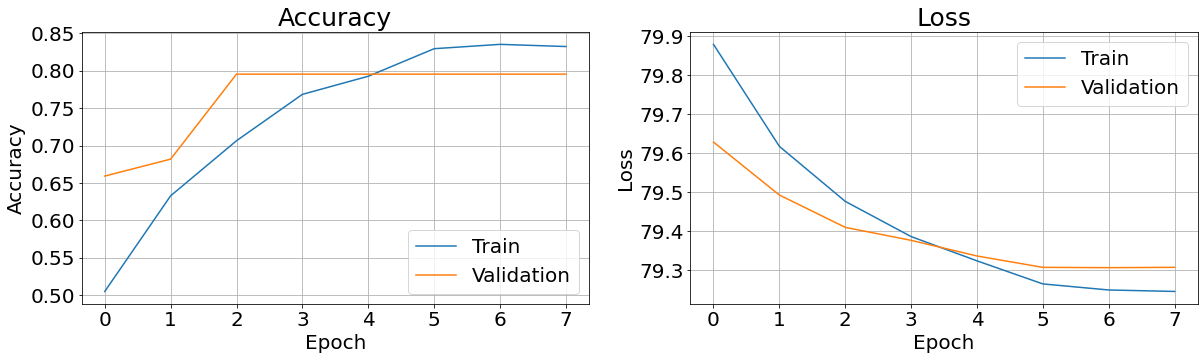

In [16]:
title_size, label_size = 25, 20
fig = plt.figure(figsize = (20, 5))
hist = history.history

plt.subplot(121)
plt.plot(hist['accuracy'])
plt.plot(hist['val_accuracy'])
plt.title('Accuracy', fontsize = title_size)
plt.ylabel('Accuracy', fontsize = label_size)
plt.xlabel('Epoch', fontsize = label_size)
plt.xticks(fontsize = label_size)
plt.yticks(fontsize = label_size)
plt.legend(['Train', 'Validation'], loc = 'lower right', fontsize = label_size)
plt.grid()

plt.subplot(122)
plt.plot(hist['loss'])
plt.plot(hist['val_loss'])
plt.title('Loss', fontsize = title_size)
plt.ylabel('Loss', fontsize = label_size)
plt.xlabel('Epoch', fontsize = label_size)
plt.xticks(fontsize = label_size)
plt.yticks(fontsize = label_size)
plt.legend(['Train', 'Validation'], loc = 'upper right', fontsize = label_size)
plt.grid()

fig.savefig(FIGURES_PATH + model_name + '_loss_accuracy.png', bbox_inches = 'tight')
plt.show()